
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [44]:
import pandas as pd

df = pd.read_csv("Human_Activity_Recognition_Using_Smartphones_Data.csv")

print("Размер:", df.shape)
print("\nТипы данных столбцов:")
print(df.dtypes)

display(df.head())

print("\nПроверка пропущенных значений:")
print("Всего пропущенных значений:", df.isnull().sum().sum())

Размер: (10299, 562)

Типы данных столбцов:
tBodyAcc-mean()-X                       float64
tBodyAcc-mean()-Y                       float64
tBodyAcc-mean()-Z                       float64
tBodyAcc-std()-X                        float64
tBodyAcc-std()-Y                        float64
                                         ...   
angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Activity                                    str
Length: 562, dtype: object


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING



Проверка пропущенных значений:
Всего пропущенных значений: 0



## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

1. Точечная диаграмма


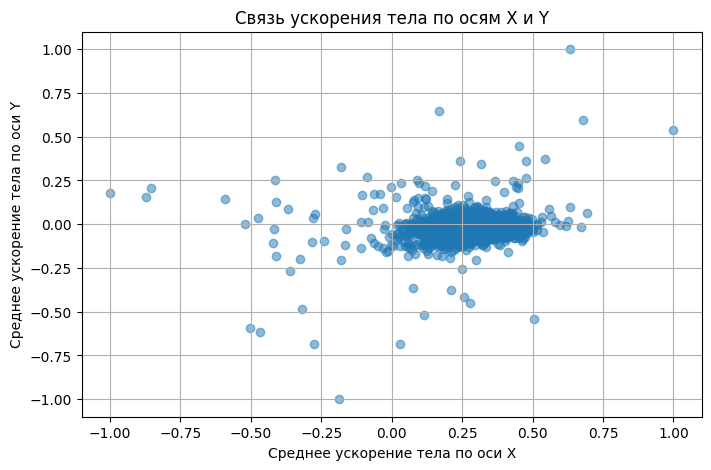

2. Тепловая карта корреляций


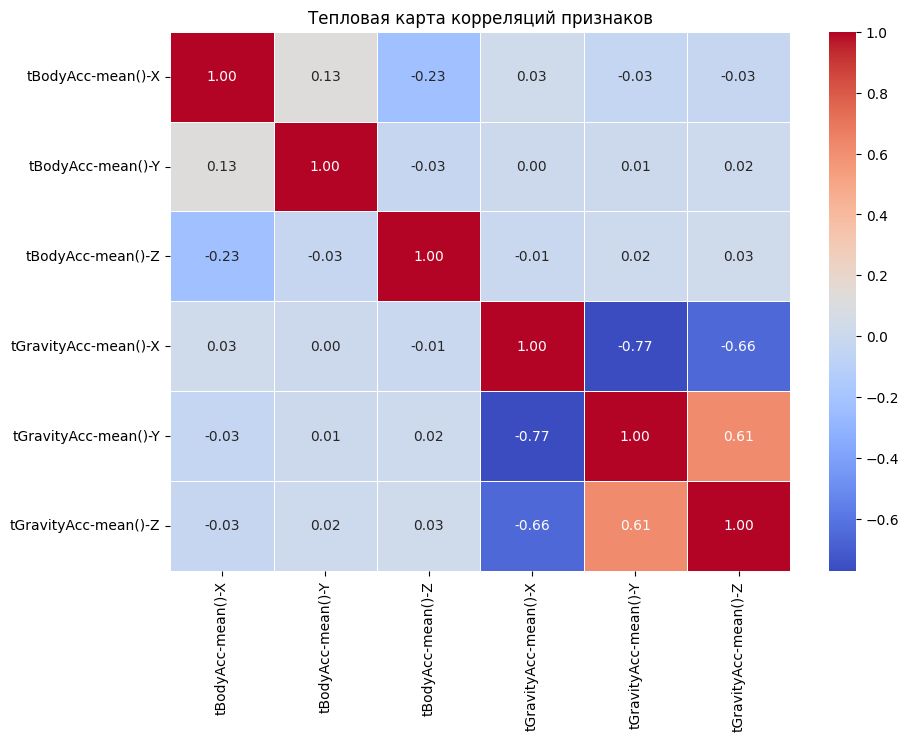

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

print("1. Точечная диаграмма")

plt.figure(figsize=(8, 5))

plt.scatter(
    df["tBodyAcc-mean()-X"],
    df["tBodyAcc-mean()-Y"],
    alpha=0.5
)

plt.xlabel("Среднее ускорение тела по оси X")
plt.ylabel("Среднее ускорение тела по оси Y")
plt.title("Связь ускорения тела по осям X и Y")
plt.grid(True)
plt.show()



print("2. Тепловая карта корреляций")

selected_columns = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-mean()-Y",
    "tBodyAcc-mean()-Z",
    "tGravityAcc-mean()-X",
    "tGravityAcc-mean()-Y",
    "tGravityAcc-mean()-Z"
]

corr_matrix = df[selected_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Тепловая карта корреляций признаков")
plt.show()

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder
import numpy as np

X = df.drop("Activity", axis=1)
le = LabelEncoder()
y = le.fit_transform(df["Activity"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("MAE :", round(mae, 4))
print("MSE :", round(mse, 4))
print("RMSE:", round(rmse, 4))

Обучающая выборка: (8239, 561)
Тестовая выборка: (2060, 561)
MAE : 0.2384
MSE : 0.0938
RMSE: 0.3063



## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [ ]:
import sklearn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

knn = KNeighborsClassifier(n_neighbors=5)

scores = cross_val_score(knn, X_train, y_train, cv=5)

print("Точность по каждой части:", scores)
print("Средняя точность:", round(scores.mean(), 4))

knn.fit(X_train, y_train)
print("Точность на тесте:", round(knn.score(X_test, y_test), 4))

Точность по каждой части: [0.96723301 0.95631068 0.95631068 0.96541262 0.9623558 ]
Средняя точность: 0.9615
Точность на тесте: 0.9592



## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

In [ ]:
from sklearn.metrics import r2_score

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

print("Линейная регрессия")
print("R2 :", round(r2_score(y_test, y_pred_lin), 4))
print("MSE:", round(mean_squared_error(y_test, y_pred_lin), 4))

Линейная регрессия
R2 : 0.9649
MSE: 0.0986


In [49]:
# 5.2 Логистическая регрессия (бинарная классификация)
# 0 - движение (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS)
# 1 - покой (SITTING, STANDING, LAYING)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

y_bin = df["Activity"].isin(["SITTING", "STANDING", "LAYING"]).astype(int)

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X, y_bin, test_size=0.2, random_state=42
)

log_reg = LogisticRegression(max_iter=10299)
log_reg.fit(Xb_train, yb_train)
yb_pred = log_reg.predict(Xb_test)

print("Логистическая регрессия")
print("Точность:", round(accuracy_score(yb_test, yb_pred), 4))

Логистическая регрессия
Точность: 1.0


In [ ]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf")
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print("SVM")
print("Точность:", round(accuracy_score(y_test, y_pred_svm), 4))

SVM
Точность: 0.9723


## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

[[ 923    0]
 [   0 1137]]


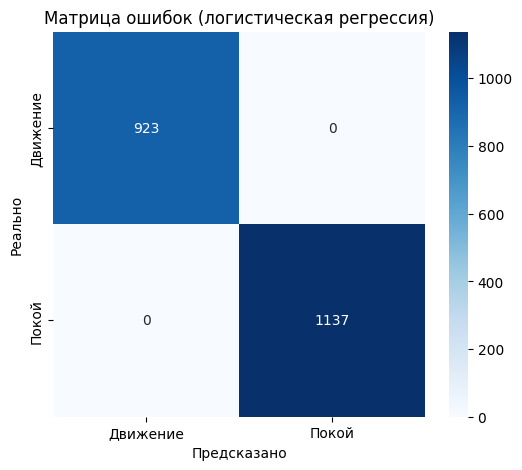

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(yb_test, yb_pred)
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Движение", "Покой"],
            yticklabels=["Движение", "Покой"])
plt.xlabel("Предсказано")
plt.ylabel("Реально")
plt.title("Матрица ошибок (логистическая регрессия)")
plt.show()


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

Найденное theta: -0.05693
Итоговая стоимость: 0.0014343
Точное theta   : -0.05694


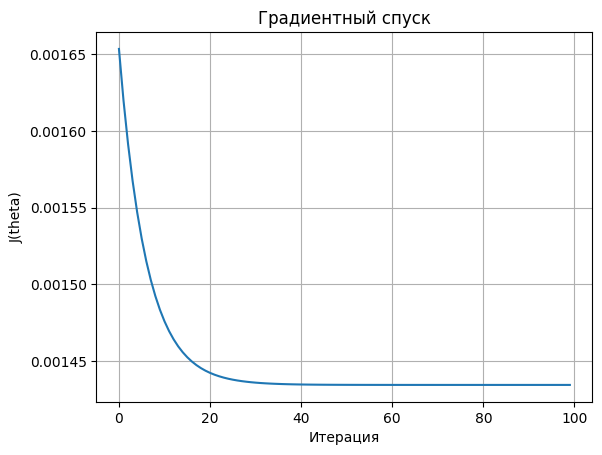

In [52]:
# берём небольшое подмножество данных (100 строк)
sub = df.sample(10299, random_state=42)
x_g = sub["tBodyAcc-mean()-X"].values
y_g = sub["tBodyAcc-mean()-Y"].values

# J(theta) = среднее (theta*x - y)^2
def cost(theta):
    return np.mean((theta * x_g - y_g) ** 2)

# производная: dJ/dtheta = 2 * среднее( x * (theta*x - y) )
def gradient(theta):
    return 2 * np.mean(x_g * (theta * x_g - y_g))

theta = 0.0          
lr = 0.5             
epochs = 100
history = []

for i in range(epochs):
    theta = theta - lr * gradient(theta)
    history.append(cost(theta))

print("Найденное theta:", round(theta, 5))
print("Итоговая стоимость:", round(history[-1], 8))

# проверка точным решением
theta_exact = np.sum(x_g * y_g) / np.sum(x_g ** 2)
print("Точное theta   :", round(theta_exact, 5))

plt.plot(history)
plt.xlabel("Итерация")
plt.ylabel("J(theta)")
plt.title("Градиентный спуск")
plt.grid(True)
plt.show()

## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


Random Forest точность: 0.9767

Топ-10 важных признаков:
angle(X,gravityMean)      0.034077
tGravityAcc-mean()-X      0.033900
tGravityAcc-max()-X       0.028378
tGravityAcc-energy()-X    0.024136
tGravityAcc-mean()-Y      0.023727
tGravityAcc-min()-X       0.023172
tGravityAcc-max()-Y       0.021737
tGravityAcc-min()-Y       0.018235
angle(Y,gravityMean)      0.018095
tGravityAcc-energy()-Y    0.013485
dtype: float64


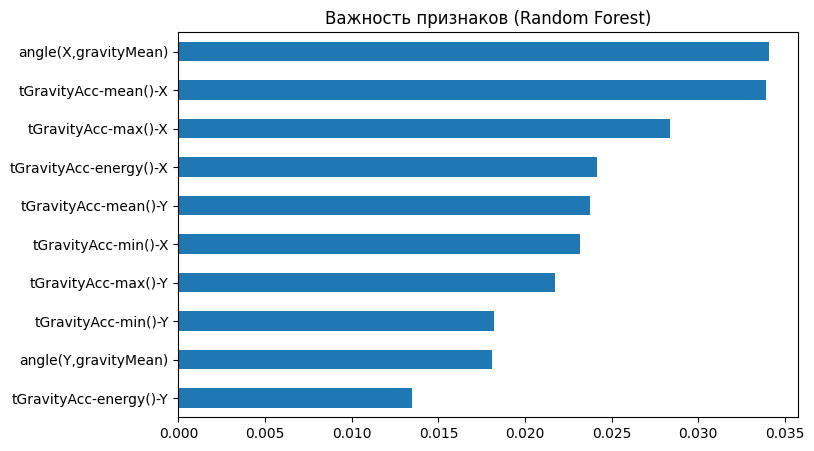

AdaBoost точность: 0.5563
Bagging  точность: 0.966


In [53]:
# 8.3 Случайный лес и важность признаков
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier
import pandas as pd

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print("Random Forest точность:", round(rf.score(X_test, y_test), 4))

importances = pd.Series(rf.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)
print("\nТоп-10 важных признаков:")
print(top10)

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind="barh")
plt.title("Важность признаков (Random Forest)")
plt.show()

# 8.4 AdaBoost и Bagging
ada = AdaBoostClassifier(n_estimators=50, random_state=42)
bag = BaggingClassifier(n_estimators=50, random_state=42)

ada.fit(X_train, y_train)
bag.fit(X_train, y_train)

print("AdaBoost точность:", round(ada.score(X_test, y_test), 4))
print("Bagging  точность:", round(bag.score(X_test, y_test), 4))

## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

In [54]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier

base_models = [
    ("rf", RandomForestClassifier(n_estimators=50, random_state=42)),
    ("svm", SVC()),
    ("log", LogisticRegression(max_iter=1000)),
]

stack = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3
)

stack.fit(X_train, y_train)
y_pred_stack = stack.predict(X_test)

print("Точность стекинга на тесте:", round(accuracy_score(y_test, y_pred_stack), 4))

Точность стекинга на тесте: 0.985



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
